# CSE457 - Lab 3: Nhận dạng từ lệnh tiếng Việt bằng Gaussian HMM

Notebook này **không chứa logic xử lý**. Toàn bộ code nằm trong `src/` (thư viện) và `scripts/` (từng bước của pipeline,
cũng là những gì `run_lab03.sh` chạy). Mỗi mục dưới đây:

1. gọi `scripts.<bước>.main([...])` để chạy đúng bước đó (kết quả ghi vào `models/` và `results/`);
2. đọc kết quả và **trực quan hóa / phân tích** bằng `src.plots`, `src.reporting`.

Có thể chạy lại từng mục độc lập, miễn là các bước trước đó đã chạy (ví dụ mục 4 cần mục 3 đã huấn luyện xong).

| Mục | Bước pipeline | Nội dung |
| :-: | :-- | :-- |
| 1 | `check_data` | Kiểm tra dataset, xem dạng sóng và tác dụng của trim |
| 2 | `src.features` | Đặc trưng 39-D (MFCC + Δ + Δ²) sau CMVN |
| 3 | `train` | Huấn luyện 5 Gaussian HMM trái-sang-phải |
| 4 | `evaluate_hmm` | Log-likelihood, confusion matrix, Viterbi, ngưỡng từ chối |
| 5 | `evaluate_dtw` | Baseline DTW và so sánh với HMM |
| 6 | `lm_rerank` | Lexicon, bigram LM, thí nghiệm E6 |
| 7 | `experiments` | Thí nghiệm E1 - E5 |
| 8 | - | Phân tích lỗi |

In [1]:
import os
from pathlib import Path

# Đảm bảo chạy từ thư mục gốc của Lab 3 (nơi có src/ và scripts/), bất kể Jupyter khởi động ở đâu.
root = Path.cwd()
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
os.chdir(root)

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from scripts import check_data, evaluate_dtw, evaluate_hmm, experiments, lm_rerank, train
from src import plots
from src.config import DISPLAY, LABELS, MODELS_DIR, RESULTS_DIR, TEST_DIR, TRAIN_DIR, FeatureConfig
from src.data import list_split
from src.dtw import dtw_distance
from src.features import extract_feat, load_wav, preprocessing_stages, trim_bounds, trim_silence
from src.reporting import build_figures, build_summary

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Thư mục làm việc:", Path.cwd())

Thư mục làm việc: /home/minh/Desktop/Speech-Audio-processing-lab/Lab03_2351260673_NguyenVanMinh


## 1. Dữ liệu

`check_data` kiểm tra định dạng WAV (16 kHz, mono, 16-bit PCM), số file mỗi lớp và rò rỉ train/test (trùng nội dung file).
Cảnh báo về số mẫu train < 6 không làm pipeline dừng; các thí nghiệm tự thích ứng với số mẫu có sẵn.

In [2]:
data = check_data.main([])
report = data["report"]
display(report.pivot_table(index="label", columns="split", values="file", aggfunc="count").reindex(LABELS))
display(report.groupby("split")[["duration_s", "peak", "rms"]].describe().T.round(3))

23:05:59 | INFO    | Số file theo lớp:
split  test  train
label             
mo        1      6
dong      1      6
len       1      6
xuong     1      6
dung      1      6


23:05:59 | INFO    | Thời lượng trung bình: 2.23 s | peak lớn nhất: 0.808


23:05:59 | WARNING | Lớp 'mo': 6 train / 1 test (khuyến nghị 6/2).


23:05:59 | WARNING | Lớp 'dong': 6 train / 1 test (khuyến nghị 6/2).


23:05:59 | WARNING | Lớp 'len': 6 train / 1 test (khuyến nghị 6/2).


23:05:59 | WARNING | Lớp 'xuong': 6 train / 1 test (khuyến nghị 6/2).


23:05:59 | WARNING | Lớp 'dung': 6 train / 1 test (khuyến nghị 6/2).


23:05:59 | INFO    | Kiểm tra dữ liệu: OK


split,test,train
label,,
mo,1,6
dong,1,6
len,1,6
xuong,1,6
dung,1,6


split              test   train
duration_s count  5.000  30.000
           mean   2.338   2.214
           std    0.212   0.196
           min    2.069   1.856
           25%    2.261   2.074
           50%    2.304   2.219
           75%    2.411   2.304
           max    2.645   2.688
peak       count  5.000  30.000
           mean   0.340   0.426
           std    0.092   0.165
           min    0.247   0.240
           25%    0.288   0.302
           50%    0.308   0.361
           75%    0.376   0.515
           max    0.483   0.808
rms        count  5.000  30.000
           mean   0.033   0.041
           std    0.008   0.012
           min    0.023   0.023
           25%    0.030   0.033
           50%    0.030   0.039
           75%    0.039   0.046
           max    0.043   0.070

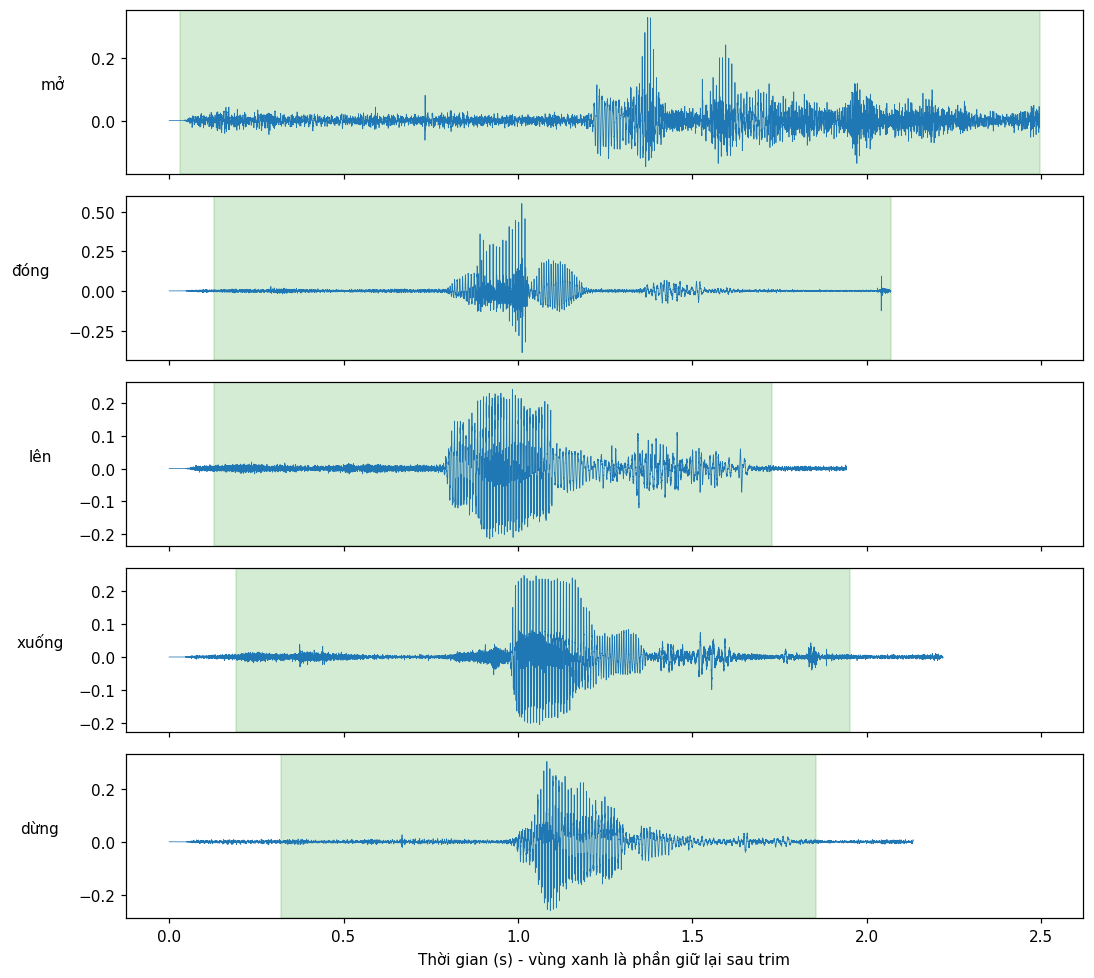

In [3]:
# Dạng sóng gốc và vùng được giữ lại sau librosa.effects.trim(top_db=30), mỗi lớp một file train.
fcfg = FeatureConfig()
fig, axes = plt.subplots(len(LABELS), 1, figsize=(10, 1.8 * len(LABELS)), sharex=True)
for ax, label in zip(axes, LABELS):
    utt = list_split(TRAIN_DIR, (label,))[0]
    y = load_wav(utt.path, fcfg)
    start, end = trim_bounds(y, fcfg)
    t = np.arange(len(y)) / fcfg.sr
    ax.plot(t, y, lw=0.5)
    ax.axvspan(start / fcfg.sr, end / fcfg.sr, color="tab:green", alpha=0.2)
    ax.set_ylabel(f"{DISPLAY[label]}", rotation=0, labelpad=25)
axes[-1].set_xlabel("Thời gian (s) - vùng xanh là phần giữ lại sau trim")
plt.tight_layout()

## 2. Đặc trưng 39-D

Pipeline: trim silence -> pre-emphasis (α = 0.97) -> MFCC (Hamming 25 ms / hop 10 ms, 26 mel, 20-8000 Hz) -> Δ, Δ² -> CMVN theo utterance.
Hàm `extract_feat` cũng hỗ trợ `use_delta=False` (13-D) cho thí nghiệm E2.

### 2.1. Tiền xử lý từng bước

raw 2.07 s -> sau trim 1.60 s -> 161 frame x 39 chiều


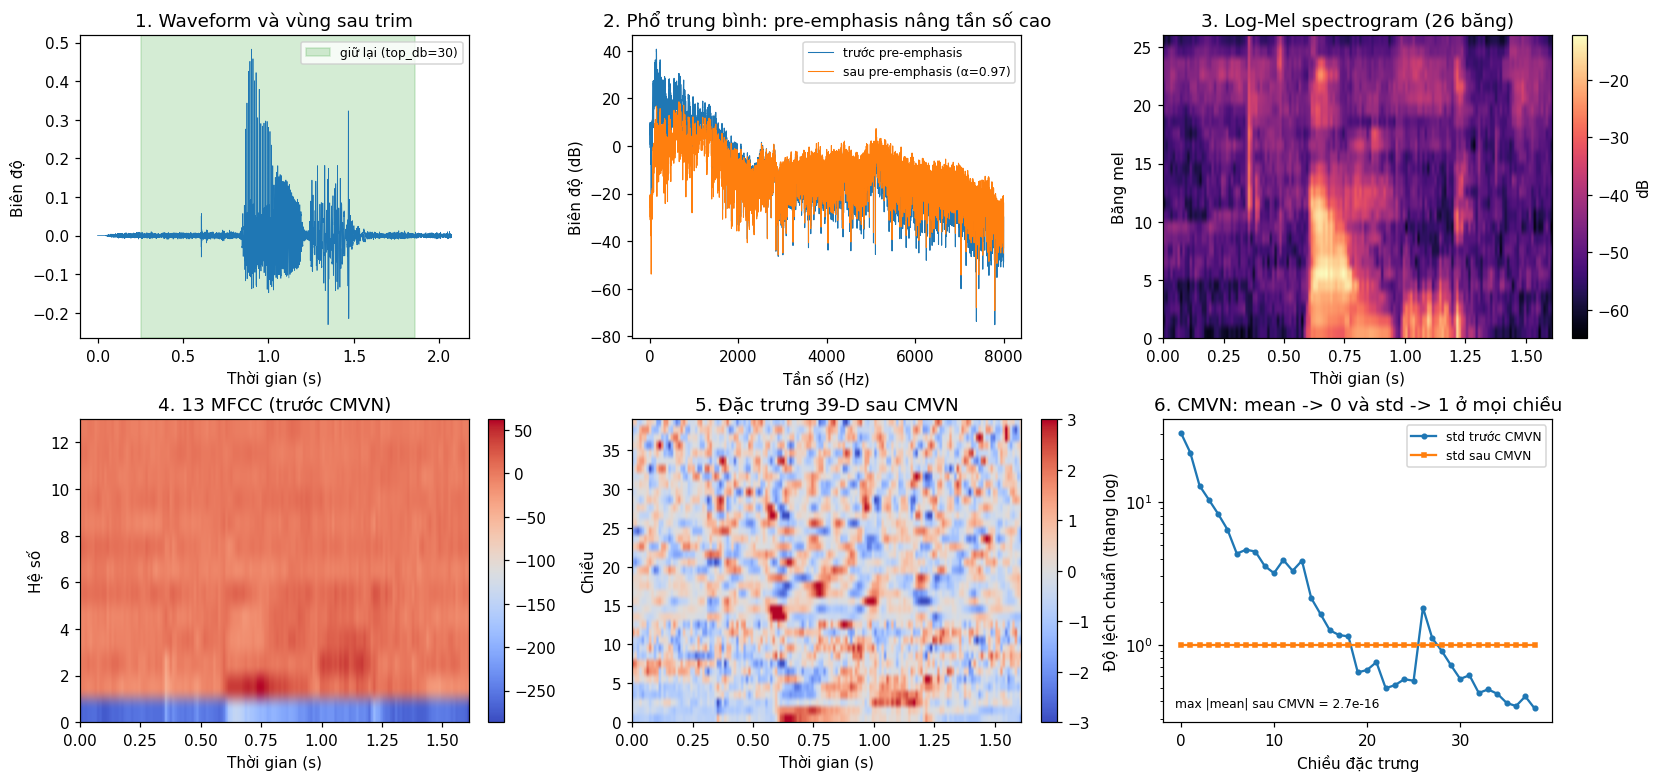

In [4]:
# Một utterance đi qua từng bước: trim -> pre-emphasis -> log-Mel -> MFCC -> CMVN.
y = load_wav(TEST_DIR / "dong" / "dong_07.wav", fcfg)
stages = preprocessing_stages(y, fcfg)
print(f"raw {len(y) / fcfg.sr:.2f} s -> sau trim {len(stages['trimmed']) / fcfg.sr:.2f} s -> {stages['feat'].shape[0]} frame x {stages['feat'].shape[1]} chiều")
fig = plots.plot_preprocessing(stages, fcfg)

### 2.2. So sánh đặc trưng hai từ

shape 39-D: (223, 39) | 13-D: (223, 13)
CMVN: mean ~ 0 -> 0.0 | std ~ 1 -> 1.0 - 1.0


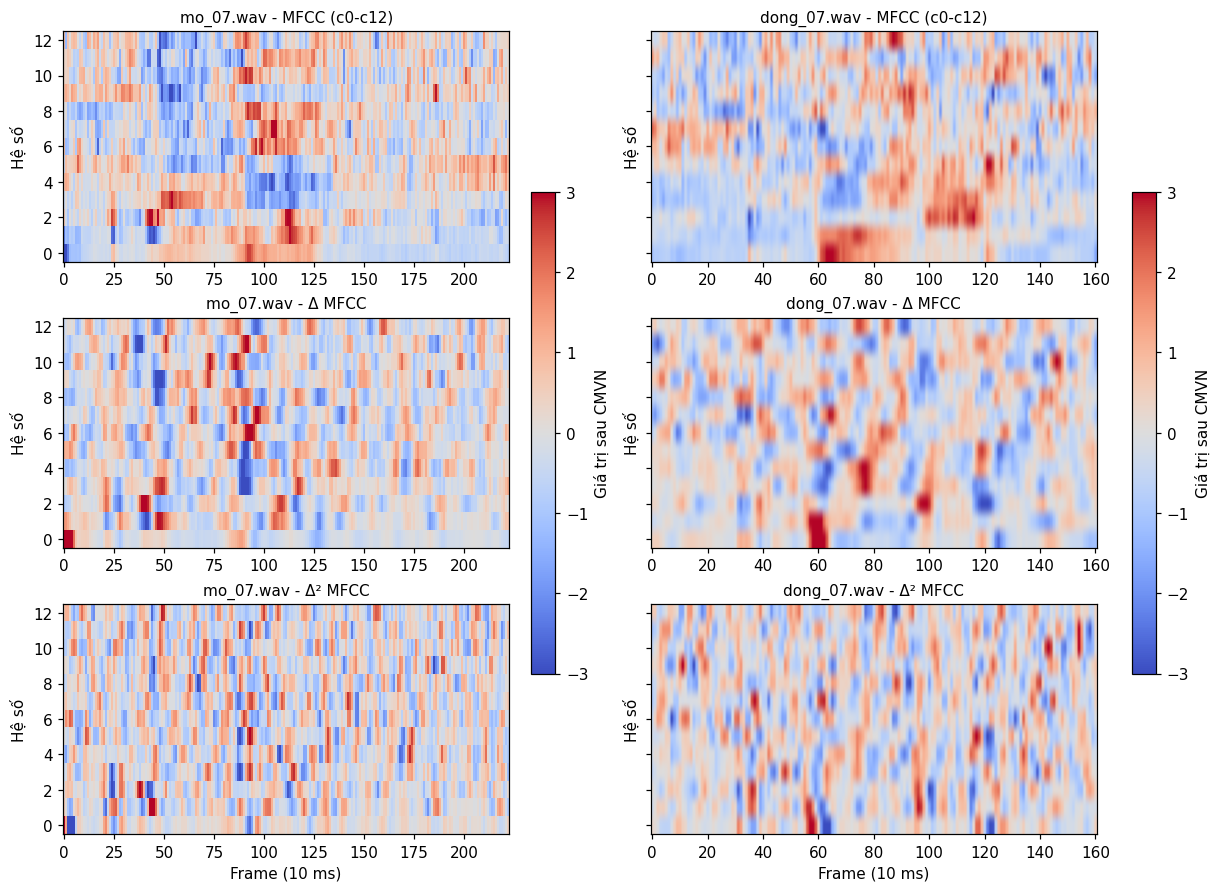

In [5]:
f_mo = extract_feat(TEST_DIR / "mo" / "mo_07.wav", fcfg)
f_dong = extract_feat(TEST_DIR / "dong" / "dong_07.wav", fcfg)
print("shape 39-D:", f_mo.shape, "| 13-D:", extract_feat(TEST_DIR / "mo" / "mo_07.wav", fcfg, use_delta=False).shape)
print("CMVN: mean ~ 0 ->", np.abs(f_mo.mean(axis=0)).max().round(8), "| std ~ 1 ->", f_mo.std(axis=0).round(3).min(), "-", f_mo.std(axis=0).round(3).max())
fig = plots.plot_mfcc_comparison({"mo_07.wav": f_mo, "dong_07.wav": f_dong})

## 3. Huấn luyện Gaussian HMM trái-sang-phải

Mỗi từ một HMM 5 trạng thái, Gaussian đường chéo; `π = [1, 0, 0, 0, 0]`, `A` khởi tạo với self-loop 0.7 / next 0.3.
Mean/cov được khởi tạo bằng cách chia đều mỗi utterance thành 5 đoạn theo thời gian rồi chạy Baum-Welch (EM).
Bước `train` kiểm tra sau huấn luyện: hội tụ, không có bước nhảy lùi / nhảy cóc trong `transmat_`.

In [6]:
trained = train.main([])
info = pd.DataFrame({l: vars(i) for l, i in trained["infos"].items()}).T
display(info.drop(columns="label"))
display(pd.DataFrame(trained["meta"]["topology"]).T)

23:06:03 | INFO    | Đặc trưng: 30 utterance, mỗi frame 39 chiều, 0.1 s


23:06:03 | INFO    | mo     | 6 utt, 1465 frame | EM 45 vòng, converged=True | LL/frame=-52.01 | 0.150 s


23:06:03 | INFO    | dong   | 6 utt, 1263 frame | EM 43 vòng, converged=True | LL/frame=-51.31 | 0.105 s


23:06:03 | INFO    | len    | 6 utt,  780 frame | EM 20 vòng, converged=True | LL/frame=-49.16 | 0.038 s


23:06:03 | INFO    | xuong  | 6 utt,  808 frame | EM 18 vòng, converged=True | LL/frame=-49.96 | 0.034 s


23:06:03 | INFO    | dung   | 6 utt, 1084 frame | EM 16 vòng, converged=True | LL/frame=-50.70 | 0.036 s


23:06:03 | INFO    | transmat_ của 'mo':
[[0.952 0.048 0.    0.    0.   ]
 [0.    0.987 0.013 0.    0.   ]
 [0.    0.    0.979 0.021 0.   ]
 [0.    0.    0.    0.978 0.022]
 [0.    0.    0.    0.    1.   ]]


23:06:03 | INFO    | Đã lưu 5 mô hình vào /home/minh/Desktop/Speech-Audio-processing-lab/Lab03_2351260673_NguyenVanMinh/models


,n_seqs,n_frames,converged,n_iter_run,train_ll_per_frame,train_time_s
mo,6,1465,True,45,-52.012,0.15
dong,6,1263,True,43,-51.306,0.105
len,6,780,True,20,-49.163,0.038
xuong,6,808,True,18,-49.962,0.034
dung,6,1084,True,16,-50.702,0.036


,converged,no_backward,no_skip,rows_sum_to_1,starts_in_state_0
mo,True,True,True,True,True
dong,True,True,True,True,True
len,True,True,True,True,True
xuong,True,True,True,True,True
dung,True,True,True,True,True


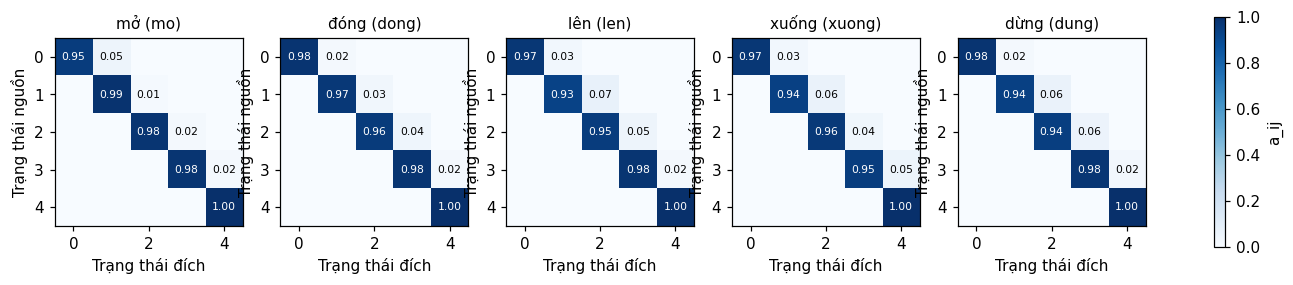

In [7]:
fig = plots.plot_transmats({l: m.transmat_ for l, m in trained["models"].items()})

## 4. Đánh giá HMM: log-likelihood, Viterbi, ma trận nhầm lẫn

* Nhận dạng ML: `argmax_w log P(X | λ_w)` bằng thuật toán Forward.
* Gióng hàng Viterbi: dùng mô hình của từ đúng để lấy đường trạng thái `q*`.
* Ngưỡng từ chối được chọn **chỉ bằng dữ liệu train** (leave-one-out, tối đa hóa Youden J) nên không rò rỉ từ tập test.

In [8]:
ev = evaluate_hmm.main([])
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ev["metrics"].items() if k not in ("per_class_accuracy",)})
cols = ["file", "label", *[f"ll_{l}" for l in LABELS], "pred", "margin"]
display(ev["table"][cols].round(1))

23:06:04 | INFO    | Accuracy (Forward/ML) = 100.0% trên 5 utterance test


23:06:04 | INFO    | Margin Top1-Top2: min=450.5, trung bình=556.7


23:06:06 | INFO    | Ngưỡng từ chối (LOO, Youden) = -53.94 | TPR=0.93 FPR=0.03 | test được chấp nhận: 100%


{'accuracy': 1.0, 'n_test': 5, 'n_states': 5, 'most_confused': [], 'mean_margin': 556.654, 'min_margin': 450.494, 'train_per_class': 6, 'train_time_ms': 362.48, 'infer_ms_per_trial': 1.126, 'reject_threshold': -53.938, 'loo_tpr': 0.933, 'loo_fpr': 0.033, 'test_accept_rate': 1.0}


,file,label,ll_mo,ll_dong,ll_len,ll_xuong,ll_dung,pred,margin
0,mo_07.wav,mo,-11769.2,-12494.4,-13766.3,-12653.0,-12805.6,mo,725.2
1,dong_07.wav,dong,-9000.1,-8356.3,-8922.3,-8942.5,-8879.7,dong,523.4
2,len_07.wav,len,-8781.2,-8401.1,-7950.6,-8741.9,-8461.0,len,450.5
3,xuong_07.wav,xuong,-11609.0,-11418.1,-12280.5,-10775.5,-11246.7,xuong,471.2
4,dung_07.wav,dung,-14980.4,-14577.5,-15465.3,-15099.6,-13964.5,dung,613.0


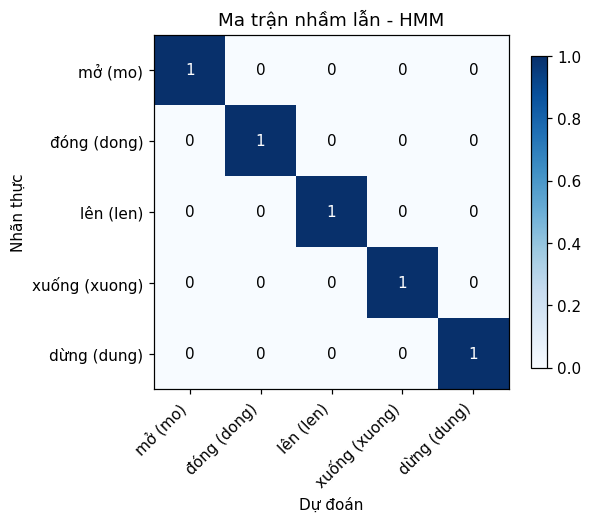

In [9]:
figs = build_figures(RESULTS_DIR, fcfg)
plt.close("all")  # các Figure vẫn hiển thị được bằng display(); đóng để inline backend không in trùng
display(figs["confusion_matrix"])

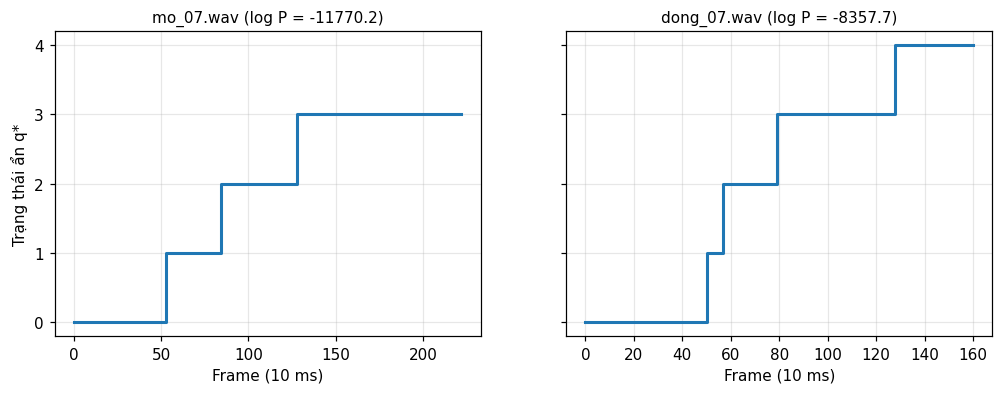

,label,state 0,state 1,state 2,state 3,state 4
mo_07.wav,mo,53,31,44,95,0
dong_07.wav,dong,50,7,22,49,33
len_07.wav,len,71,15,21,31,16
xuong_07.wav,xuong,73,22,31,12,67
dung_07.wav,dung,76,16,16,36,115


In [10]:
display(figs["viterbi_paths"])
vit = pd.DataFrame({f: v["durations"] for f, v in ev["viterbi"].items()}, index=[f"state {i}" for i in range(5)]).T
vit.insert(0, "label", [v["label"] for v in ev["viterbi"].values()])
display(vit)

Đường Viterbi phải **đơn điệu không giảm** (topology trái-sang-phải); số frame ở mỗi trạng thái phản ánh độ dài tương đối của từng
đoạn âm học. Trạng thái cuối là trạng thái hấp thụ nên thường nhận phần đuôi còn lại của utterance (kể cả khoảng lặng chưa được trim hết).

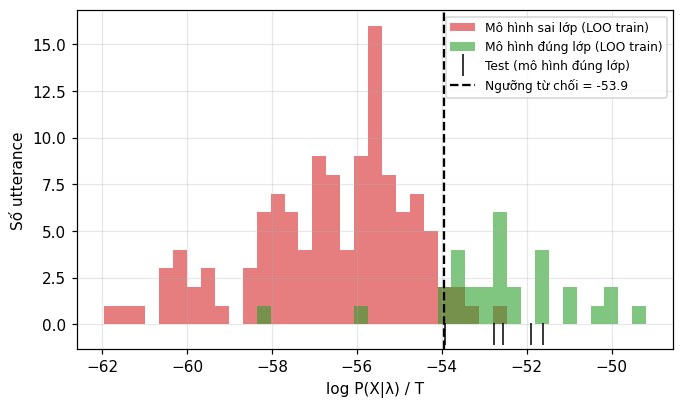

In [11]:
display(figs["score_distribution"])

## 5. Baseline DTW và so sánh công bằng

DTW dùng **cùng** đặc trưng 39-D, cùng tập train (làm template) và cùng tập test với HMM; nhận dạng 1-NN theo khoảng cách DTW chuẩn hóa.

23:06:06 | INFO    | Accuracy (DTW 1-NN) = 100.0% trên 5 utterance test


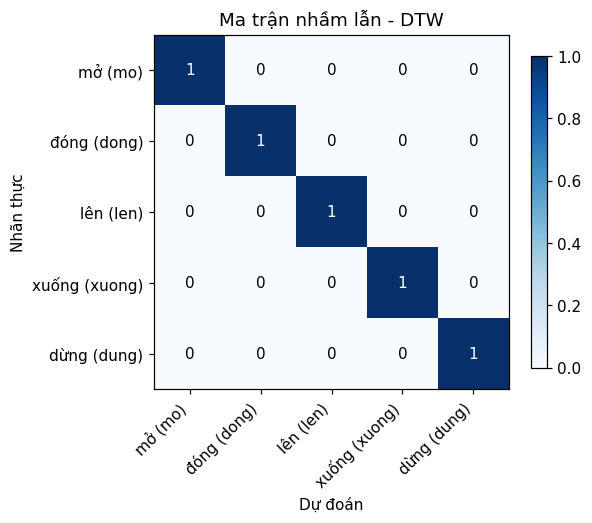

## So sánh DTW và Gaussian HMM

| Chỉ số | DTW (Lab 2) | Gaussian HMM (Lab 3) |
| --- | --- | --- |
| Accuracy (%) | 100.0 | 100.0 |
| Số mẫu train / lớp | 6 | 6 |
| Thời gian train (ms) | 0.01 | 362.5 |
| Thời gian test / trial (ms) | 49.10 | 1.13 |
| Cặp từ dễ nhầm nhất | không có | không có |
| Cơ chế alignment | Warping path | Viterbi state path |


In [12]:
dtw_out = evaluate_dtw.main([])
display(figs["confusion_matrix_dtw"])
sections = build_summary(RESULTS_DIR).split("\n## ")
display(Markdown("## " + next(s for s in sections if s.startswith("So sánh"))))

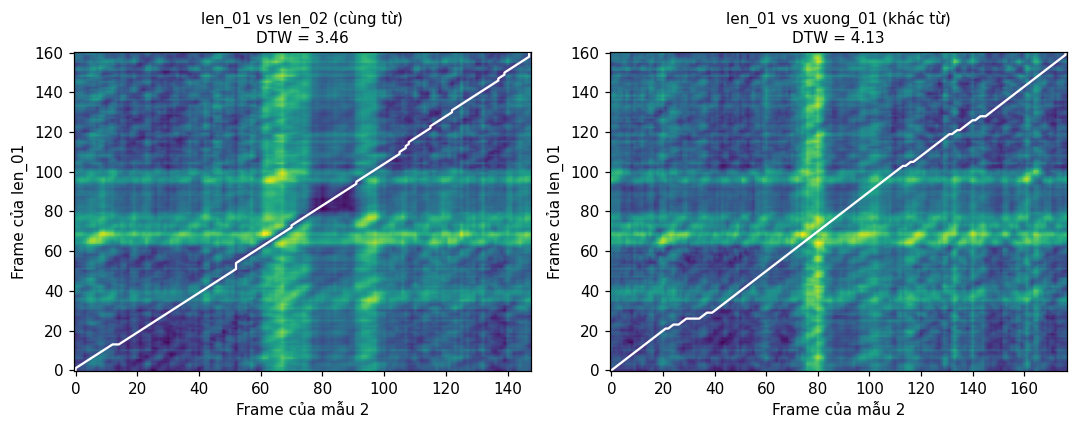

In [13]:
# Minh họa đường warping DTW giữa hai lần phát âm của cùng một từ và hai từ khác nhau.
a = extract_feat(TRAIN_DIR / "len" / "len_01.wav", fcfg)
pairs = {"len_01 vs len_02 (cùng từ)": extract_feat(TRAIN_DIR / "len" / "len_02.wav", fcfg),
         "len_01 vs xuong_01 (khác từ)": extract_feat(TRAIN_DIR / "xuong" / "xuong_01.wav", fcfg)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, b) in zip(axes, pairs.items()):
    dist, path = dtw_distance(a, b, return_path=True)
    from scipy.spatial.distance import cdist
    ax.imshow(cdist(a, b), origin="lower", aspect="auto", cmap="viridis")
    ax.plot([j for _, j in path], [i for i, _ in path], "w-", lw=1.5)
    ax.set_title(f"{title}\nDTW = {dist:.2f}", fontsize=10)
    ax.set_xlabel("Frame của mẫu 2"); ax.set_ylabel("Frame của len_01")
plt.tight_layout()

## 6. Lexicon, bigram LM và thí nghiệm E6

`lexicon.txt` ánh xạ từ sang âm vị; `corpus.txt` là các câu lệnh mẫu để đếm bigram với làm trơn Add-k (k = 0.5).
Xếp hạng lại: `Score(w) = (1/T) log P_AM(X|w) + λ_LM · log P_LM(w | w_prev)`.

In [14]:
lm_out = lm_rerank.main([])
display(lm_out["bigram_table"].set_index("prev").round(3))
display(pd.Series({w: " ".join(p) for w, p in lm_out["lexicon"].items()}, name="phones"))

23:06:07 | INFO    | lexicon | mo     -> m o


23:06:07 | INFO    | lexicon | dong   -> d o ng


23:06:07 | INFO    | lexicon | len    -> l e n


23:06:07 | INFO    | lexicon | xuong  -> x uo ng


23:06:07 | INFO    | lexicon | dung   -> z u ng


23:06:07 | INFO    | P(cur | prev), k=0.5:
          mo   dong    len  xuong   dung
prev                                    
<s>    0.294  0.294  0.176  0.176  0.059
mo     0.059  0.059  0.412  0.294  0.176
dong   0.059  0.059  0.294  0.412  0.176
len    0.059  0.059  0.059  0.059  0.765
xuong  0.059  0.059  0.059  0.059  0.765
dung   0.412  0.412  0.059  0.059  0.059


23:06:07 | INFO    | E6 - accuracy theo λ_LM:
lambda_lm    0.0    0.1    0.3    1.0
condition                            
SNR 0 dB   0.444  0.533  0.489  0.489
SNR 10 dB  0.600  0.600  0.600  0.667
SNR 5 dB   0.556  0.533  0.489  0.556
clean      1.000  1.000  1.000  1.000


,mo,dong,len,xuong,dung
prev,,,,,
<s>,0.294,0.294,0.176,0.176,0.059
mo,0.059,0.059,0.412,0.294,0.176
dong,0.059,0.059,0.294,0.412,0.176
len,0.059,0.059,0.059,0.059,0.765
xuong,0.059,0.059,0.059,0.059,0.765
dung,0.412,0.412,0.059,0.059,0.059


mo           m o
dong      d o ng
len        l e n
xuong    x uo ng
dung      z u ng
Name: phones, dtype: object

lambda_lm,0.0,0.1,0.3,1.0
condition,,,,
SNR 0 dB,0.444,0.533,0.489,0.489
SNR 10 dB,0.600,0.600,0.600,0.667
SNR 5 dB,0.556,0.533,0.489,0.556
clean,1.000,1.000,1.000,1.000


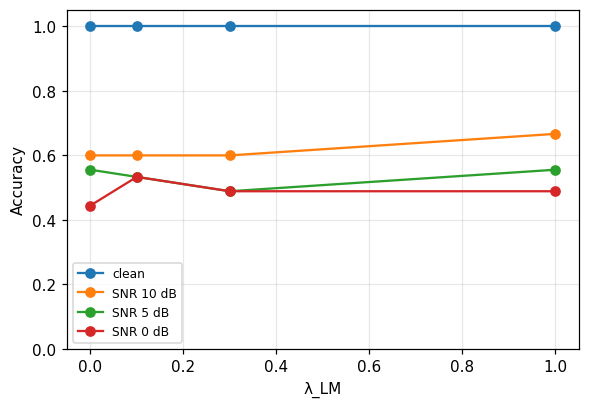

In [15]:
e6 = lm_out["e6"]
display(e6.pivot(index="condition", columns="lambda_lm", values="accuracy").round(3))
fig = plots.plot_lambda_curves(e6)

Tập test sạch đã đạt accuracy tối đa nên LM chưa có gì để cải thiện; tác dụng của LM chỉ quan sát được ở các điều kiện có nhiễu,
nơi âm học bắt đầu sai. λ_LM quá lớn làm LM lấn át bằng chứng âm học nên accuracy giảm trở lại.

## 7. Thí nghiệm E1 - E5

Mỗi thí nghiệm là một hàm trong `src/experiments.py`; script `experiments` chạy chúng và ghi `results/e*.csv`.
Có thể chạy riêng từng thí nghiệm, ví dụ `experiments.main(["--only", "E1", "E3"])`.

In [16]:
exp = experiments.main([])
figs = build_figures(RESULTS_DIR, fcfg)
plt.close("all")

23:06:08 | INFO    | E1 xong trong 1.2 s -> results/e1_states.csv
 n_states  train_acc  test_acc converged  mean_iters  train_ll  test_ll  train_time_s
        3        1.0       1.0       5/5        15.4   -52.509  -53.517         0.120
        5        1.0       1.0       5/5        28.4   -50.626  -52.557         0.349
        7        1.0       1.0       5/5        34.6   -49.732  -52.358         0.532


23:06:09 | INFO    | E2 xong trong 0.6 s -> results/e2_features.csv
features  train_acc  test_acc converged  mean_iters  train_ll  test_ll  train_time_s
    13-D        1.0       1.0       5/5        15.6   -15.382  -16.432         0.145
    39-D        1.0       1.0       5/5        28.4   -50.626  -52.557         0.342


23:06:13 | INFO    | E3 xong trong 3.9 s -> results/e3_covariance.csv
cov_type  train_acc  test_acc converged  mean_iters  train_ll  test_ll  train_time_s  ll_gap
    diag        1.0       1.0       5/5        28.4   -50.626  -52.557         0.346   1.931
    full        1.0       0.6       5/5        19.2   -41.120  -60.039         3.367  18.919


23:06:18 | INFO    | E4 xong trong 5.1 s -> results/e4_data_size.csv
 n_train method  mean_acc  std_acc  runs
       1    HMM      0.60    0.126     5
       1    DTW      0.64    0.196     5
       2    HMM      0.88    0.098     5
       2    DTW      0.84    0.080     5
       3    HMM      1.00    0.000     5
       3    DTW      0.80    0.126     5
       4    HMM      1.00    0.000     5
       4    DTW      1.00    0.000     5
       6    HMM      1.00    0.000     1
       6    DTW      1.00    0.000     1


23:06:22 | INFO    | E5 xong trong 4.1 s -> results/e5_robustness.csv
condition method  mean_acc  std_acc  runs
    clean    HMM     1.000    0.000     1
    clean    DTW     1.000    0.000     1
SNR 20 dB    HMM     0.800    0.000     3
SNR 20 dB    DTW     0.800    0.000     3
SNR 10 dB    HMM     0.600    0.000     3
SNR 10 dB    DTW     0.600    0.000     3
 SNR 5 dB    HMM     0.533    0.094     3
 SNR 5 dB    DTW     0.600    0.000     3
 SNR 0 dB    HMM     0.467    0.094     3
 SNR 0 dB    DTW     0.467    0.094     3


### E1 - Số trạng thái

Quan sát `train_ll`/`test_ll`: thêm trạng thái luôn làm likelihood trên train tốt hơn, nhưng cần xem test có tốt theo không.

,n_states,train_acc,test_acc,converged,mean_iters,train_ll,test_ll,train_time_s
0,3,1.0,1.0,5/5,15.4,-52.509,-53.517,0.120
1,5,1.0,1.0,5/5,28.4,-50.626,-52.557,0.349
2,7,1.0,1.0,5/5,34.6,-49.732,-52.358,0.532


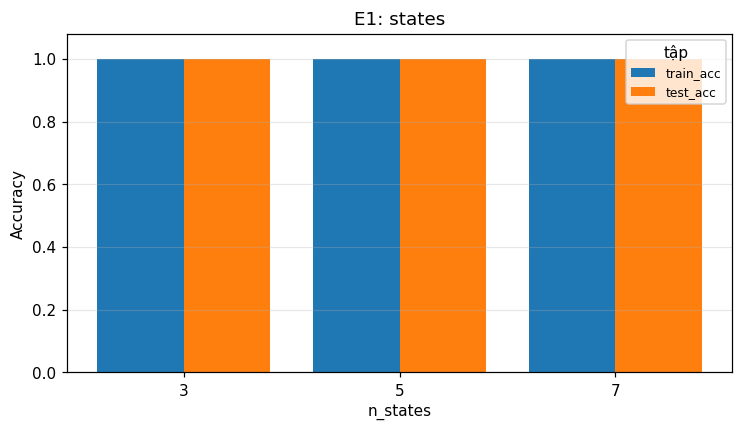

In [17]:
display(exp["E1"].round(3))
display(figs["e1_states"])

### E2 - Chiều đặc trưng 13-D vs 39-D

`train_ll`/`test_ll` của hai cấu hình **không so sánh trực tiếp** được vì số chiều khác nhau; chỉ so accuracy.

,features,train_acc,test_acc,converged,mean_iters,train_ll,test_ll,train_time_s
0,13-D,1.0,1.0,5/5,15.6,-15.382,-16.432,0.145
1,39-D,1.0,1.0,5/5,28.4,-50.626,-52.557,0.342


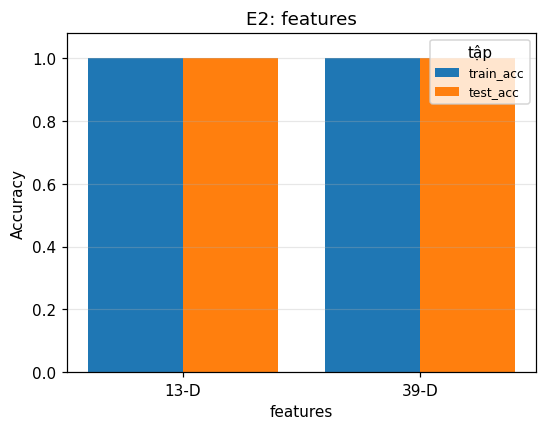

In [18]:
display(exp["E2"].round(3))
display(figs["e2_features"])

### E3 - `diag` vs `full`

`ll_gap = train_ll - test_ll` đo mức overfit: ma trận `full` có rất nhiều tham số so với số frame huấn luyện.

,cov_type,train_acc,test_acc,converged,mean_iters,train_ll,test_ll,train_time_s,ll_gap
0,diag,1.0,1.0,5/5,28.4,-50.626,-52.557,0.346,1.931
1,full,1.0,0.6,5/5,19.2,-41.120,-60.039,3.367,18.919


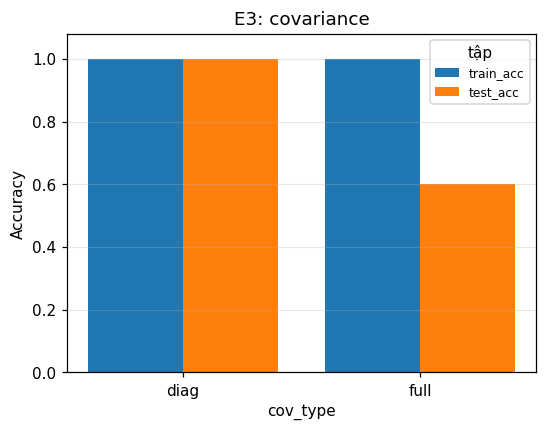

In [19]:
display(exp["E3"].round(3))
display(figs["e3_covariance"])

### E4 - Số mẫu train mỗi lớp (HMM vs DTW)

Mỗi điểm là trung bình trên nhiều lần lấy mẫu con ngẫu nhiên; cột sai số là độ lệch chuẩn.

,n_train,method,mean_acc,std_acc,runs
0,1,HMM,0.60,0.126,5
1,1,DTW,0.64,0.196,5
2,2,HMM,0.88,0.098,5
3,2,DTW,0.84,0.080,5
4,3,HMM,1.00,0.000,5
5,3,DTW,0.80,0.126,5
6,4,HMM,1.00,0.000,5
7,4,DTW,1.00,0.000,5
8,6,HMM,1.00,0.000,1
9,6,DTW,1.00,0.000,1


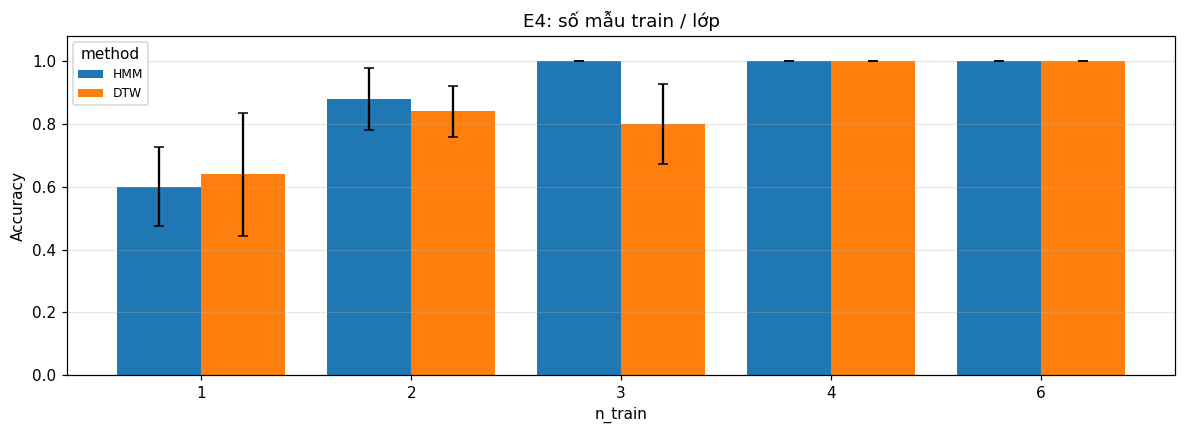

In [20]:
display(exp["E4"].round(3))
display(figs["e4_data_size"])

### E5 - Độ bền vững với nhiễu trắng

Mô hình huấn luyện trên dữ liệu sạch; nhiễu cộng vào tập test theo SNR. Xem thêm mục 8 về vai trò của bước trim.

,condition,method,mean_acc,std_acc,runs
0,clean,HMM,1.000,0.000,1
1,clean,DTW,1.000,0.000,1
2,SNR 20 dB,HMM,0.800,0.000,3
3,SNR 20 dB,DTW,0.800,0.000,3
4,SNR 10 dB,HMM,0.600,0.000,3
5,SNR 10 dB,DTW,0.600,0.000,3
6,SNR 5 dB,HMM,0.533,0.094,3
7,SNR 5 dB,DTW,0.600,0.000,3
8,SNR 0 dB,HMM,0.467,0.094,3
9,SNR 0 dB,DTW,0.467,0.094,3


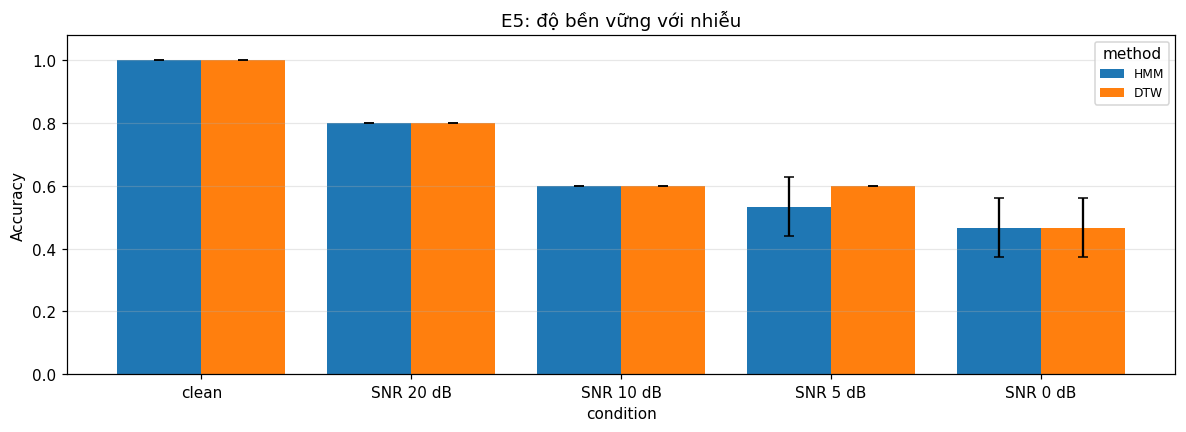

In [21]:
display(exp["E5"].round(3))
display(figs["e5_robustness"])

## 8. Phân tích lỗi

Trên tập test sạch, các mẫu có margin Top-1 - Top-2 nhỏ nhất là những mẫu "suýt sai". Tiếp theo là kiểm tra vì sao nhiễu làm
accuracy tụt mạnh ở E5 ngay cả với SNR 20 dB.

,file,label,pred,margin
2,len_07.wav,len,len,450.5
3,xuong_07.wav,xuong,xuong,471.2
1,dong_07.wav,dong,dong,523.4
4,dung_07.wav,dung,dung,613.0
0,mo_07.wav,mo,mo,725.2


,file,raw (s),trim sạch (s),trim SNR 20 dB (s)
0,mo_07.wav,2.26,2.23,2.26
1,dong_07.wav,2.07,1.60,2.07
2,len_07.wav,2.41,1.54,2.41
3,xuong_07.wav,2.30,2.05,2.30
4,dung_07.wav,2.65,2.58,2.65


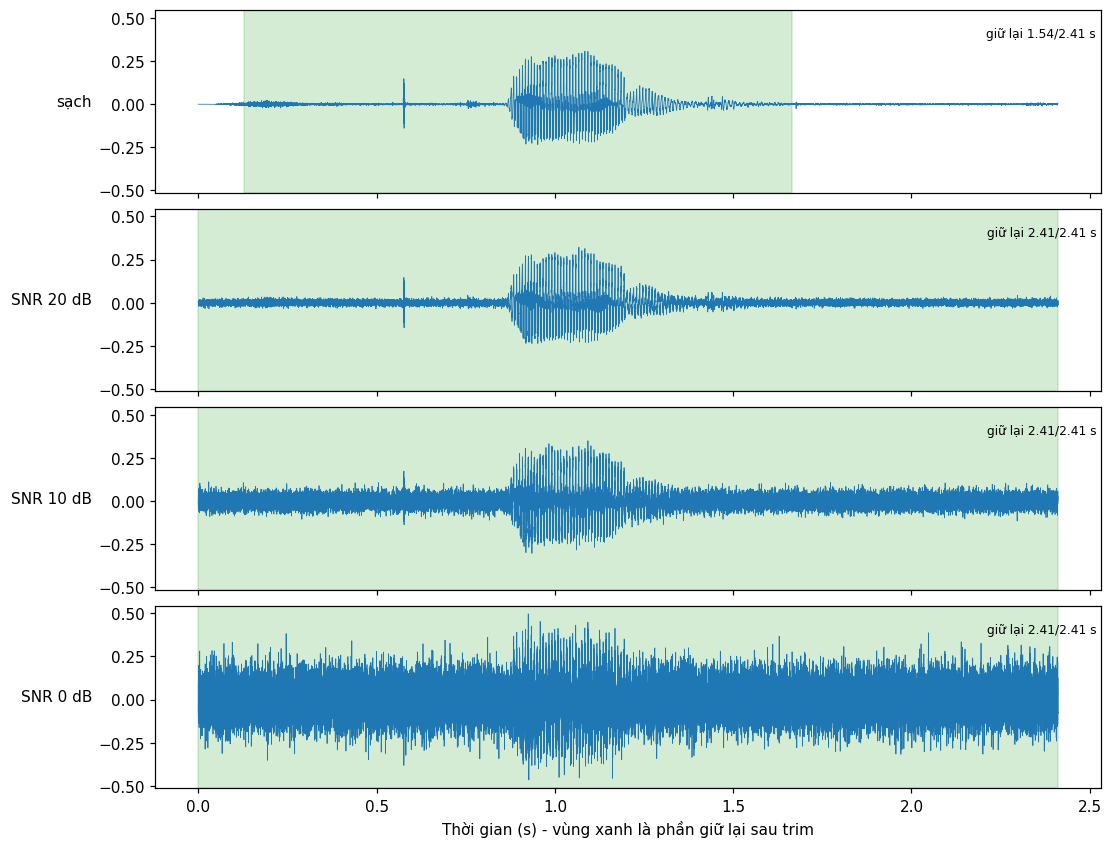

In [22]:
tbl = ev["table"].sort_values("margin")[["file", "label", "pred", "margin"]]
display(tbl.head(5).round(1))

# So sánh độ dài sau trim giữa file sạch và file có nhiễu 20 dB: nếu trim không còn cắt được thì phần lặng/nhiễu
# đi vào HMM và chiếm trọn các trạng thái.
from src.noise import add_white_noise
rng = np.random.default_rng(0)
y = load_wav(TEST_DIR / "len" / "len_07.wav", fcfg)
signals = {"sạch": y}
signals |= {f"SNR {snr} dB": add_white_noise(y, snr, rng) for snr in (20, 10, 0)}
fig = plots.plot_noise_trim({k: (v, trim_bounds(v, fcfg)) for k, v in signals.items()}, fcfg.sr)
rows = []
for utt in list_split(TEST_DIR):
    y = load_wav(utt.path, fcfg)
    rows.append({"file": utt.name, "raw (s)": len(y) / fcfg.sr, "trim sạch (s)": len(trim_silence(y, fcfg)) / fcfg.sr,
                 "trim SNR 20 dB (s)": len(trim_silence(add_white_noise(y, 20, rng), fcfg)) / fcfg.sr})
display(pd.DataFrame(rows).round(2))

Nếu cột `trim SNR 20 dB` gần bằng `raw`, ngưỡng cố định `top_db = 30` không còn tách được tiếng nói khỏi nền khi có nhiễu, và
HMM (không có mô hình im lặng riêng) phải giải thích cả đoạn nhiễu bằng các trạng thái của từ. Đây là hạn chế của front-end, không phải của
bản thân mô hình HMM; cải thiện khả thi là dùng VAD thích nghi hoặc thêm trạng thái/mô hình im lặng.